## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

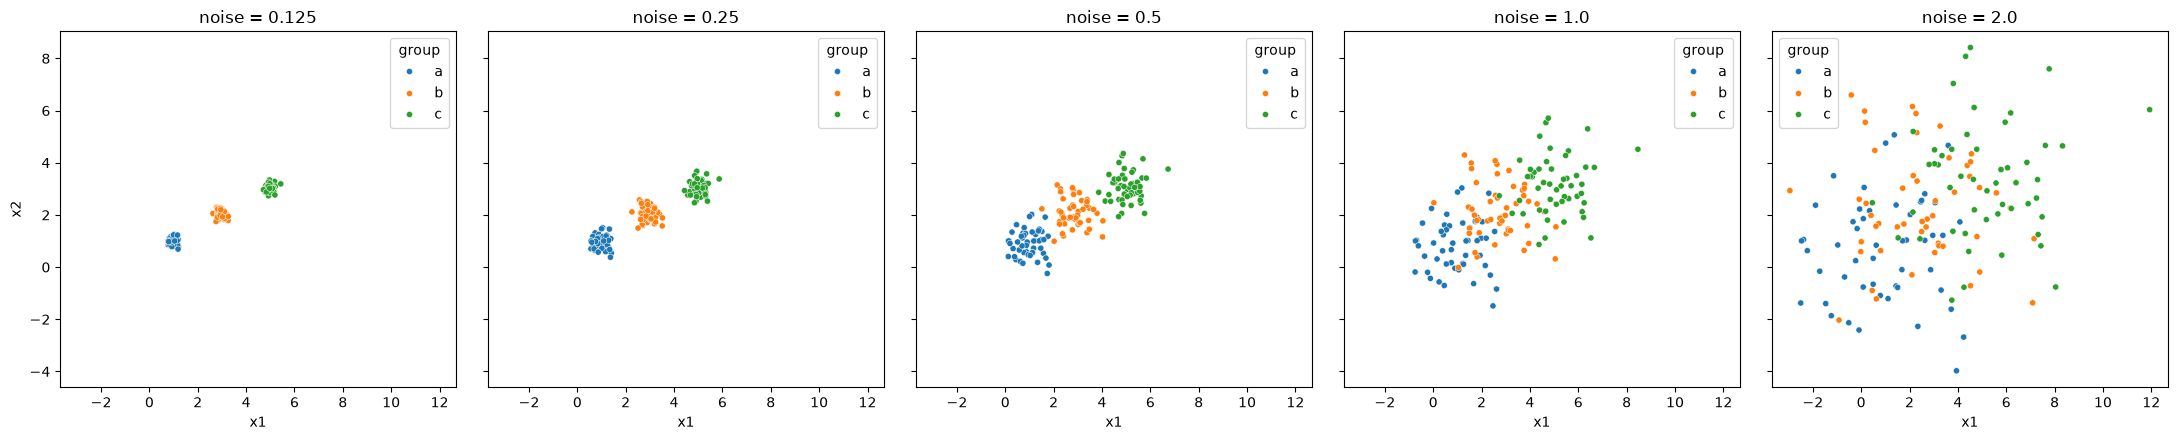

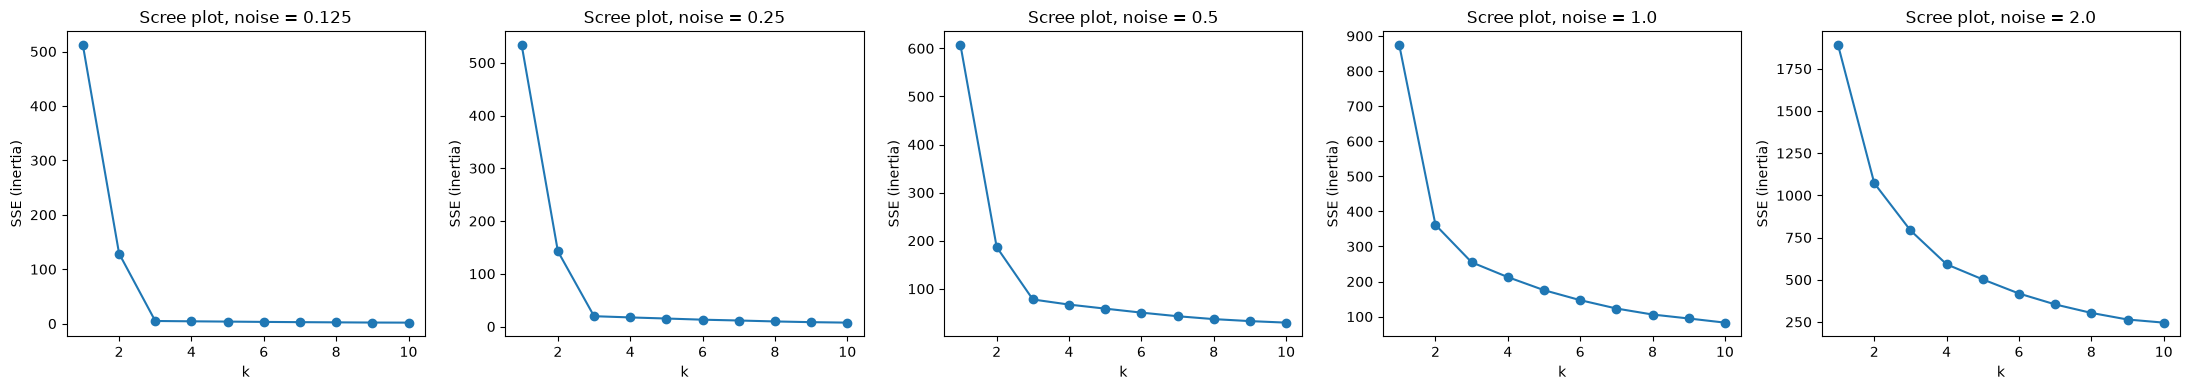

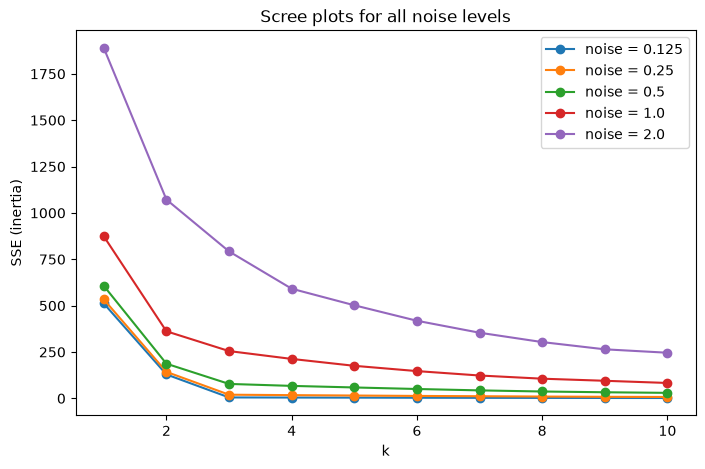

(148, 5)
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
Duplicate countries: 0
       Spending (2020 USD)  Percent of GDP  Percent of Government Spending  \
count           148.000000      148.000000                      148.000000   
mean          13153.747670        0.019619                        0.061510   
std           68005.236120        0.015033                        0.046207   
min               8.622460        0.000054                        0.004896   
25%             204.877177        0.010413                        0.031352   
50%             959.535443        0.015324                        0.047402   
75%            5289.998320        0.024327                        0.084681   
max          778397.200000        0.098470                        0.303027   

       Spending per Capita  
count       

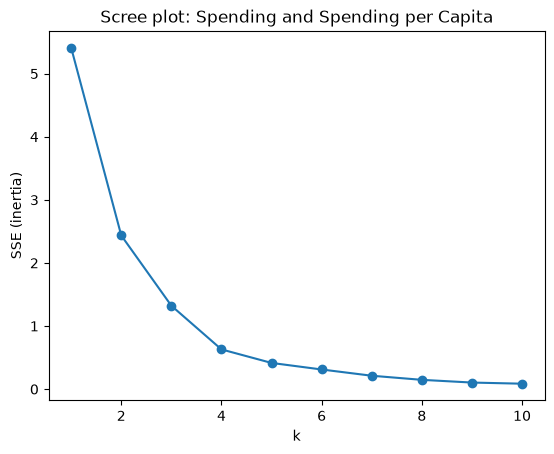

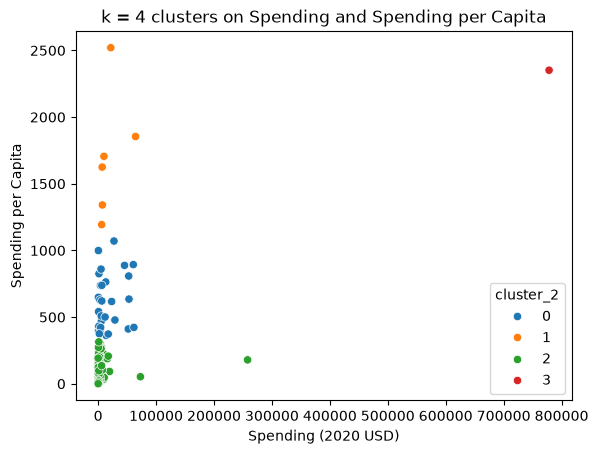

                      Country  cluster_2
144  United States of America          3
Cluster 0 (30 countries): ['Russia', 'United Kingdom', 'Germany', 'France', 'Japan', 'Korea, South', 'Italy', 'Australia', 'Canada', 'Spain', 'Poland', 'Netherlands']
Cluster 1 (6 countries): ['Saudi Arabia', 'Israel', 'Singapore', 'Norway', 'Kuwait', 'Oman']
Cluster 2 (111 countries): ['China', 'India', 'Brazil', 'Turkey', 'Iran', 'Pakistan', 'Algeria', 'Colombia', 'Indonesia', 'Mexico', 'Thailand', 'Ukraine']
Cluster 3 (1 countries): ['United States of America']
          Spending (2020 USD)                                              \
                        count           mean           std            min   
cluster_2                                                                   
0                        30.0   17077.591354  20583.053357     405.790494   
1                         6.0   19443.362047  22861.507114    6095.708713   
2                       111.0    4859.185065  25405.739131      

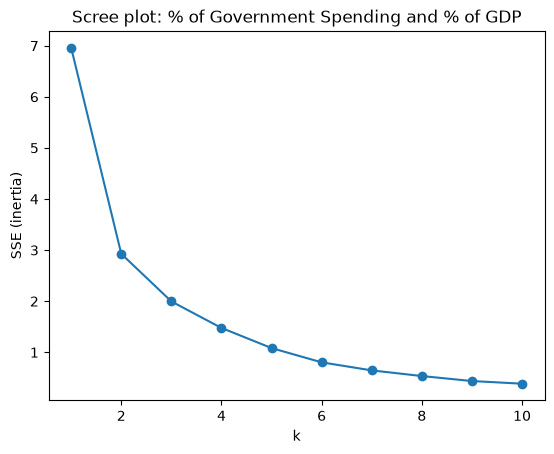

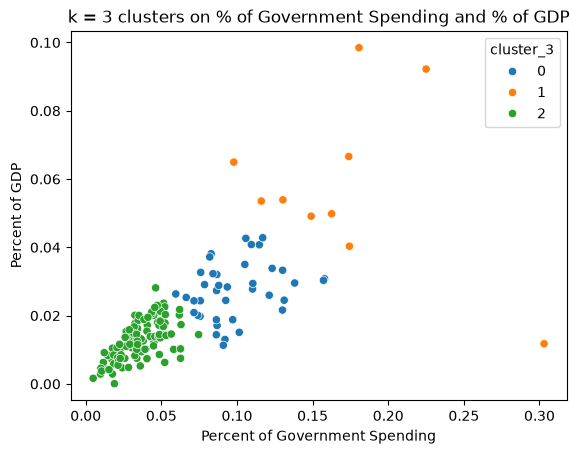

                      Country  cluster_3
144  United States of America          0
Cluster 0 (39 countries): ['United States of America', 'India', 'Russia', 'Korea, South', 'Turkey', 'Iran', 'Taiwan', 'Singapore', 'Colombia', 'Ukraine', 'Iraq', 'Chile']
Cluster 1 (10 countries): ['Saudi Arabia', 'Israel', 'Pakistan', 'Algeria', 'Kuwait', 'Oman', 'Azerbaijan', 'Jordan', 'Belarus', 'Armenia']
Cluster 2 (99 countries): ['China', 'United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Brazil', 'Spain', 'Poland', 'Netherlands']
          Percent of Government Spending                                \
                                   count      mean       std       min   
cluster_3                                                                
0                                   39.0  0.098683  0.024125  0.059520   
1                                   10.0  0.171289  0.058725  0.097882   
2                                   99.0  0.035777  0.014549  0.004896   

  

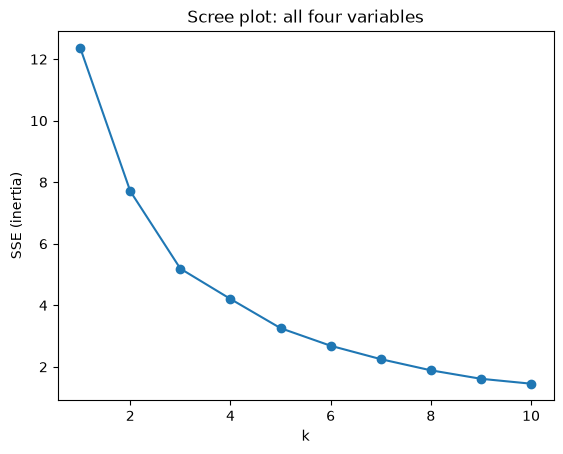

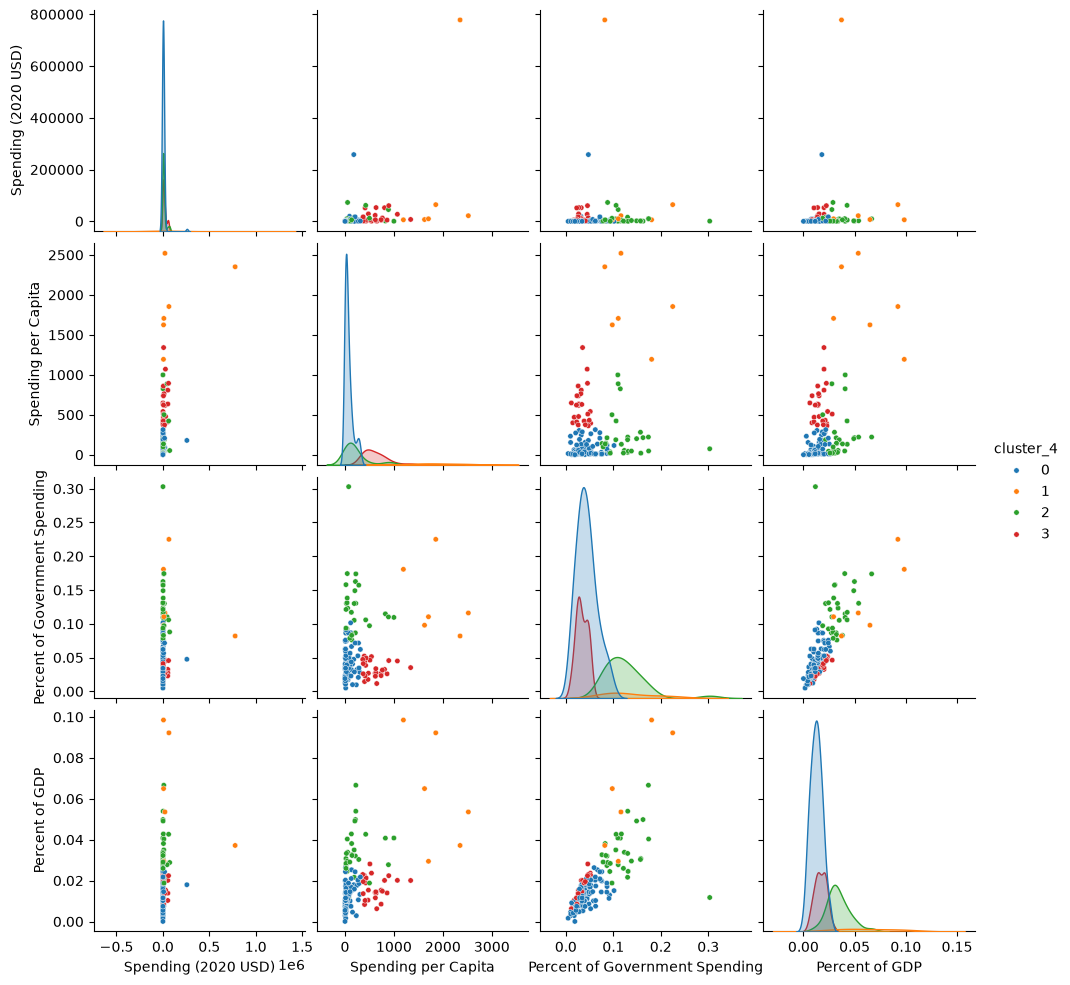

                      Country  cluster_4
144  United States of America          1
Cluster 0 (86 countries): ['China', 'Brazil', 'Turkey', 'Indonesia', 'Mexico', 'Thailand', 'Chile', 'Romania', 'Bangladesh', 'Egypt', 'Philippines', 'Malaysia']
Cluster 1 (6 countries): ['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']
Cluster 2 (30 countries): ['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia', 'Ukraine', 'Iraq', 'Morocco', 'Myanmar']
Cluster 3 (26 countries): ['United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Spain', 'Poland', 'Netherlands', 'Norway', 'Switzerland']
          Spending (2020 USD)                                             \
                        count           mean            std          min   
cluster_4                                                                  
0                        86.0    4513.543790   27841.230783     8.622460   
1                   

In [4]:
# Your Phase 1 solution to the problem goes here.
# 1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

# 1.2
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
for ax, (noise, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax, s=20)
    ax.set_title(f'noise = {noise}')
plt.tight_layout()
plt.show()

# 1.3
ks = range(1, 11)
sse = {}
for noise, df in datasets.items():
    X = df[['x1', 'x2']]
    sse[noise] = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, noise in zip(axes, datasets):
    ax.plot(ks, sse[noise], marker='o')
    ax.set_title(f'Scree plot, noise = {noise}')
    ax.set_xlabel('k')
    ax.set_ylabel('SSE (inertia)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for noise in datasets:
    plt.plot(ks, sse[noise], marker='o', label=f'noise = {noise}')
plt.xlabel('k')
plt.ylabel('SSE (inertia)')
plt.title('Scree plots for all noise levels')
plt.legend()
plt.show()

# 2.1
raw = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = raw[raw['Year'] == 2020].dropna().copy()
df = df.drop(columns=['index', 'Year']).reset_index(drop=True)
print(df.shape)
print(df.dtypes)
print('Duplicate countries:', df['Country'].duplicated().sum())
print(df.describe())

# 2.2
def maxmin(x):
    return (x - x.min()) / (x.max() - x.min())

def scree(X, title):
    ks = range(1, 11)
    sse = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    plt.plot(ks, sse, marker='o')
    plt.xlabel('k')
    plt.ylabel('SSE (inertia)')
    plt.title(title)
    plt.show()

def cluster_members(df, col, k):
    for c in range(k):
        names = df.loc[df[col] == c].sort_values('Spending (2020 USD)', ascending=False)['Country'].tolist()
        print(f'Cluster {c} ({len(names)} countries): {names[:12]}')

vars2 = ['Spending (2020 USD)', 'Spending per Capita']
X2 = df[vars2].apply(maxmin)
scree(X2, 'Scree plot: Spending and Spending per Capita')

k2 = 4
df['cluster_2'] = KMeans(n_clusters=k2, n_init=10, random_state=0).fit_predict(X2)
sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_2', palette='tab10')
plt.title('k = 4 clusters on Spending and Spending per Capita')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_2']])
cluster_members(df, 'cluster_2', k2)
print(df.groupby('cluster_2')[vars2].describe())

# 2.3
vars3 = ['Percent of Government Spending', 'Percent of GDP']
X3 = df[vars3].apply(maxmin)
scree(X3, 'Scree plot: % of Government Spending and % of GDP')

k3 = 3
df['cluster_3'] = KMeans(n_clusters=k3, n_init=10, random_state=0).fit_predict(X3)
sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_3', palette='tab10')
plt.title('k = 3 clusters on % of Government Spending and % of GDP')
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_3']])
cluster_members(df, 'cluster_3', k3)
print(df.groupby('cluster_3')[vars3].describe())

# 2.4
vars4 = vars2 + vars3
X4 = df[vars4].apply(maxmin)
scree(X4, 'Scree plot: all four variables')

k4 = 4
df['cluster_4'] = KMeans(n_clusters=k4, n_init=10, random_state=0).fit_predict(X4)
sns.pairplot(df[vars4 + ['cluster_4']], hue='cluster_4', palette='tab10', plot_kws={'s': 15})
plt.show()

print(df.loc[df['Country'] == 'United States of America', ['Country', 'cluster_4']])
cluster_members(df, 'cluster_4', k4)
print(df.groupby('cluster_4')[vars4].describe())



In [5]:
# ANSWERS
# 1.2: As noise increases, the clusters become more spread out and increasingly overlap, and by a noise level of 2.0 they are no longer visually distinguishable.
# 1.3: At low noise levels the scree plot shows a clear elbow at k = 3, but as noise increases the curve becomes smoother and the elbow disappears, which makes selecting k much less certain.
# 1.4: SSE decreases sharply while each additional cluster separates genuinely distinct groups and only marginally once k exceeds the true number of groups, so the elbow appears at k = 3 in this simulation and weakens as noise causes the groups to overlap.
# 2.1: The data requires little additional cleaning, but the variables differ greatly in scale and are heavily skewed by outliers such as the United States, so they must be normalized before clustering.
# 2.2: Using k = 4, the United States forms its own cluster due to its exceptionally high total spending, while the remaining countries are grouped primarily by spending per capita, which largely reflects national wealth.
# 2.3: When spending is measured as a share of GDP and government spending, the United States falls into a moderate group, while countries such as Saudi Arabia, Oman, and Israel stand out for devoting an unusually large share of their resources to the military.
# 2.4: Clustering on all four variables combines the patterns from parts 2 and 3, placing the United States with Saudi Arabia, Israel, and the Gulf states and separating Western Europe into its own group, although the elbow is less distinct.
# 2.5: Yes, the analysis showed that which countries appear to be the largest military spenders depends heavily on whether spending is measured in absolute terms or relative to the economy, although the results were sensitive to outliers and the choice of variables.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 19cdc173c6cfe2f4bdbf84dc8bbee4b0256ba576
- **AI tool and model used:** ChatGPT Sol 5.6

### *Prompts used

1. How can I redo this code to make sure it answers the questions asked more efficently and ensures the data is clean?

### *AI-proposed changes


AI-proposed changes
1. Remove repeated code by creating reusable functions for max-min normalization, scree plots, KMeans clustering, and cluster summaries.
2. Improve data cleaning by checking for missing values, duplicate countries, incorrect data types, and invalid numeric values before clustering.
3. Verify that filtering the SIPRI dataset to 2020 and removing missing values produces the expected 148 countries.
4. Improve the Q1 scatterplots by keeping consistent axis limits and colors across all five noise levels to make cluster overlap easier to compare.
5. Improve the Q1 scree plots by displaying the curves together and accounting for differences in SSE scales when comparing noise levels.
6. Make the elbow method easier to interpret by printing the SSE values for each value of \(k\) alongside the scree plots.
7. Add protection against division by zero in the max-min normalization function when a variable has no variation.
8. Make the clustering results easier to interpret by including cluster sizes, mean spending values, and country membership alongside the existing .describe() tables.
9. Improve the Q2 scatterplots by using normalized variables for clearer visualization and labeling notable countries such as the United States.
10. Verify the conclusions for Q2 by checking the actual countries assigned to each cluster and comparing how the results change when using different combinations of spending variables.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Reusable functions would reduce repeated code, but I would keep separate sections for each question so the notebook remains easy to follow. |
| 2 | Accept | Checking missing values, duplicates, and data types helps prevent incorrect values from affecting the clustering results. |
| 3 | Accept | Verifying the 2020 filtering confirms that the dataset contains the expected 148 countries before clustering. |
| 4 | Accept | Consistent axis limits and colors make it easier to compare how increasing noise affects the clusters across the five scatterplots. |
| 5 | Modify | Displaying scree plots together would improve comparisons, but I would keep separate plots when SSE scales differ significantly. |
| 6 | Accept | Printing SSE values alongside the scree plots makes it easier to identify the elbow and justify the selected number of clusters. |
| 7 | Accept | Handling division by zero prevents errors when normalizing variables that contain identical values. |
| 8 | Modify | Adding cluster sizes and mean values would improve interpretation, but I would keep the existing `.describe()` tables for more detailed summaries. |
| 9 | Modify | Normalized scatterplots would make variables easier to compare, but I would only label notable countries when the labels do not overcrowd the graphs. |
| 10 | Accept | Checking country membership and comparing different spending variables helps verify that the conclusions reflect the actual clustering results. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

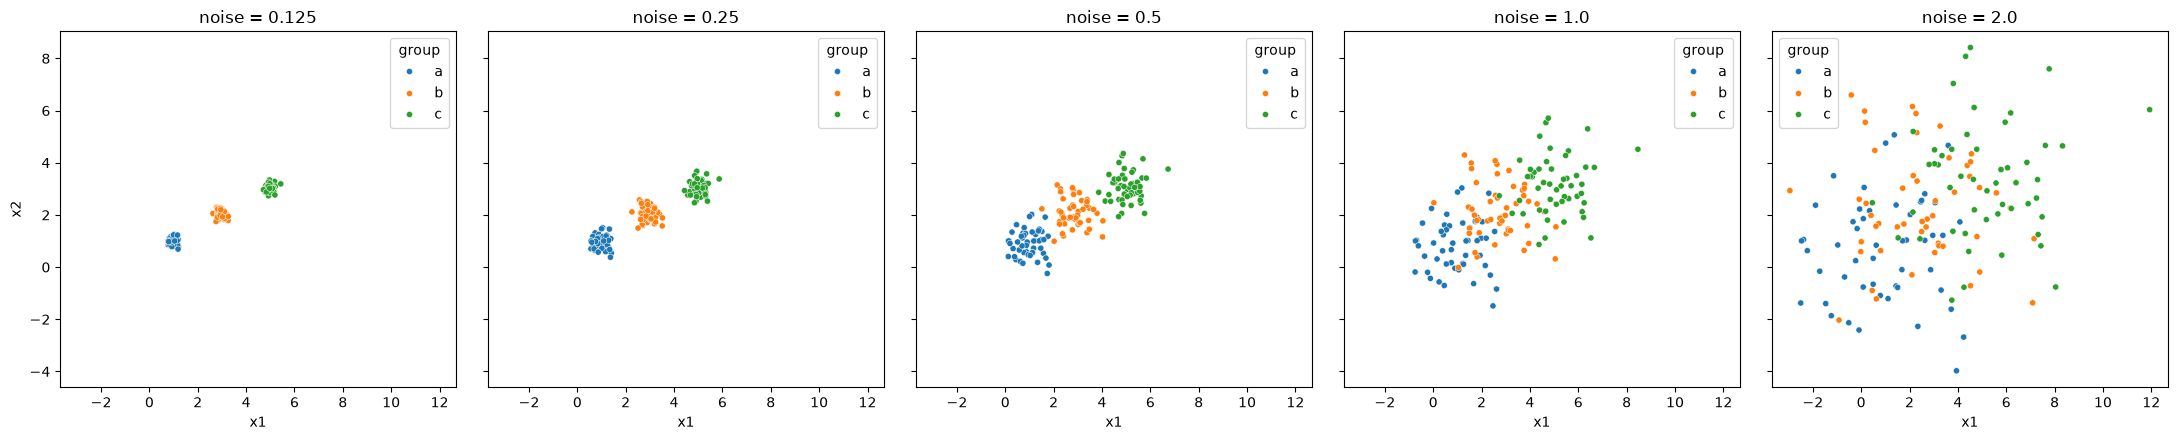

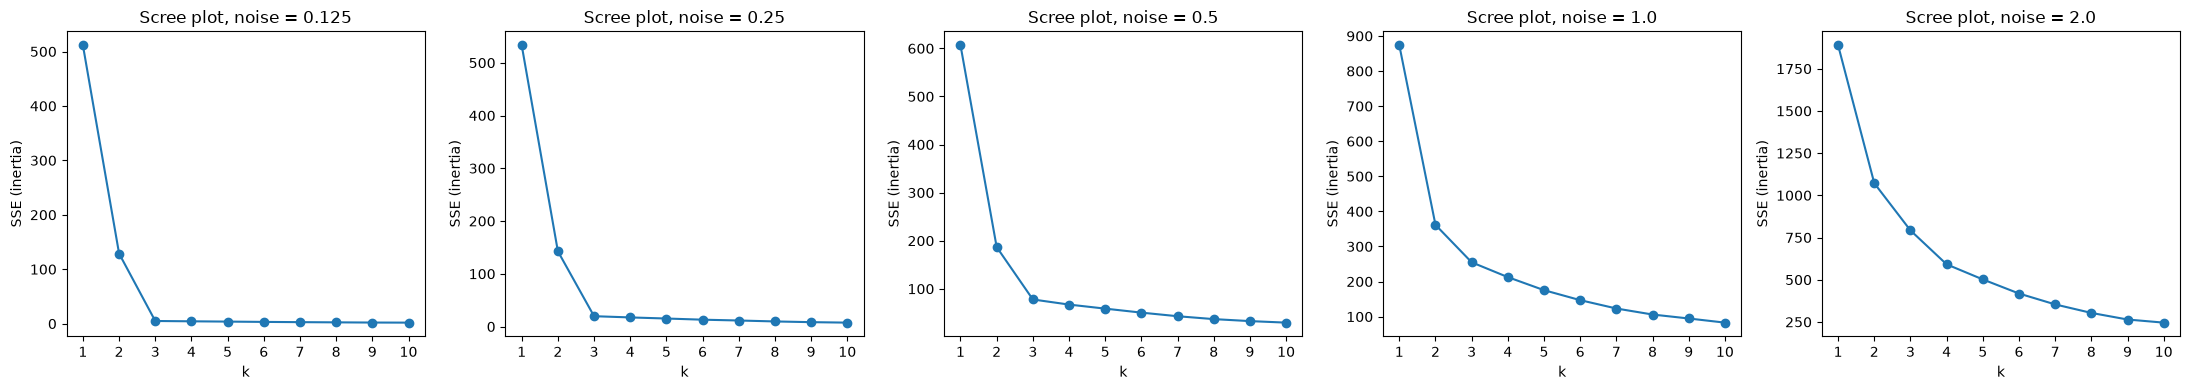

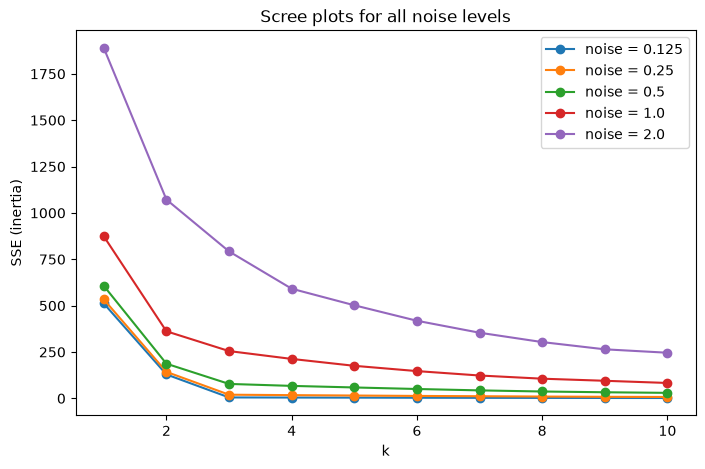

SSE values by noise level:
     0.125   0.250   0.500   1.000    2.000
k                                          
1   511.61  533.25  606.62  873.69  1889.20
2   128.89  142.72  186.78  361.59  1071.81
3     4.91   19.65   77.82  254.91   792.27
4     4.33   17.33   67.19  212.65   591.18
5     3.80   15.24   58.74  175.47   501.88
6     3.23   13.04   50.45  147.00   418.35
7     2.79   11.49   42.96  123.19   353.84
8     2.42    9.72   36.96  106.02   303.45
9     2.06    8.35   32.81   94.74   264.42
10    1.91    7.47   29.65   82.95   245.99
Dataset shape: (148, 5)
Number of countries: 148
Missing values:
 Country                           0
Spending (2020 USD)               0
Percent of GDP                    0
Percent of Government Spending    0
Spending per Capita               0
dtype: int64
Duplicate countries: 0
Data types:
 Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Sp

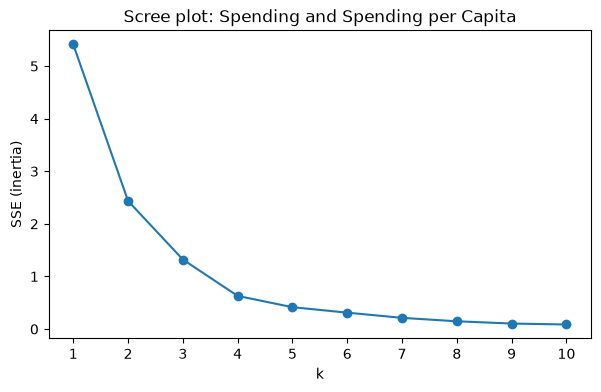

SSE values for Scree plot: Spending and Spending per Capita:
 k   SSE
 1 5.411
 2 2.435
 3 1.322
 4 0.629
 5 0.415
 6 0.311
 7 0.212
 8 0.147
 9 0.104
10 0.086


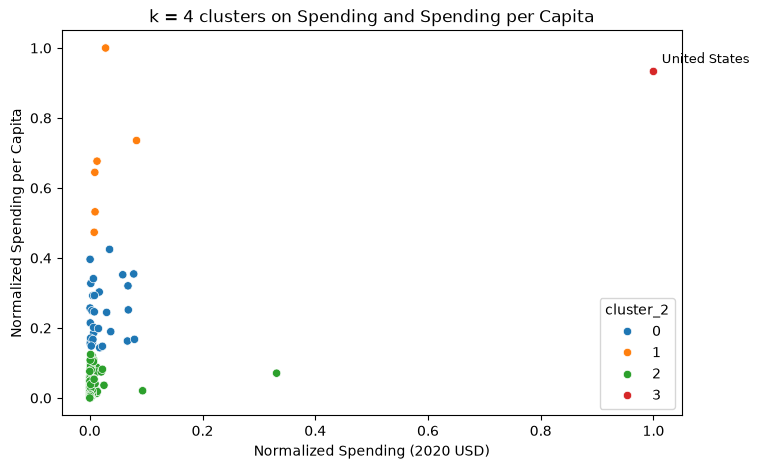

United States cluster:
                      Country  cluster_2
144  United States of America          3
Cluster 0 (30 countries): ['Russia', 'United Kingdom', 'Germany', 'France', 'Japan', 'Korea, South', 'Italy', 'Australia', 'Canada', 'Spain', 'Poland', 'Netherlands']
Cluster 1 (6 countries): ['Saudi Arabia', 'Israel', 'Singapore', 'Norway', 'Kuwait', 'Oman']
Cluster 2 (111 countries): ['China', 'India', 'Brazil', 'Turkey', 'Iran', 'Pakistan', 'Algeria', 'Colombia', 'Indonesia', 'Mexico', 'Thailand', 'Ukraine']
Cluster 3 (1 countries): ['United States of America']

Cluster sizes:
cluster_2
0     30
1      6
2    111
3      1
dtype: int64

Cluster means:
           Spending (2020 USD)  Spending per Capita
cluster_2                                          
0                    17077.591              607.479
1                    19443.362             1706.722
2                     4859.185               80.061
3                   778397.200             2351.632

Cluster describe table

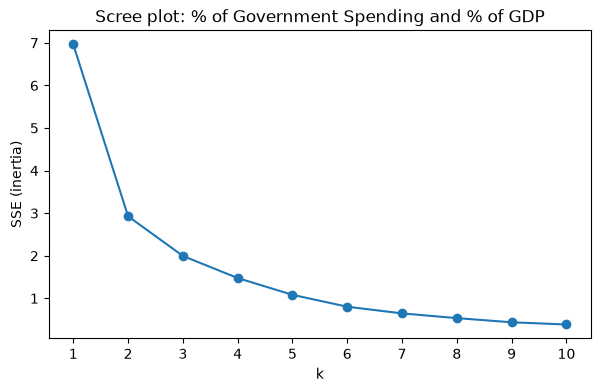

SSE values for Scree plot: % of Government Spending and % of GDP:
 k   SSE
 1 6.961
 2 2.927
 3 1.996
 4 1.477
 5 1.083
 6 0.803
 7 0.646
 8 0.535
 9 0.438
10 0.386


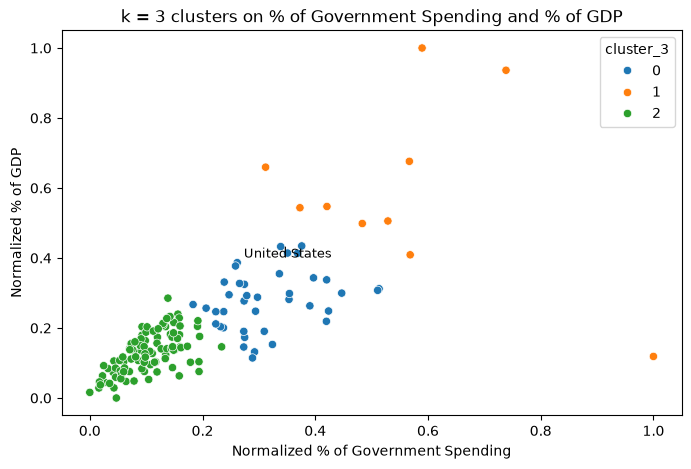

United States cluster:
                      Country  cluster_3
144  United States of America          0
Cluster 0 (39 countries): ['United States of America', 'India', 'Russia', 'Korea, South', 'Turkey', 'Iran', 'Taiwan', 'Singapore', 'Colombia', 'Ukraine', 'Iraq', 'Chile']
Cluster 1 (10 countries): ['Saudi Arabia', 'Israel', 'Pakistan', 'Algeria', 'Kuwait', 'Oman', 'Azerbaijan', 'Jordan', 'Belarus', 'Armenia']
Cluster 2 (99 countries): ['China', 'United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Brazil', 'Spain', 'Poland', 'Netherlands']

Cluster sizes:
cluster_3
0    39
1    10
2    99
dtype: int64

Cluster means:
           Percent of Government Spending  Percent of GDP
cluster_3                                                
0                                   0.099           0.027
1                                   0.171           0.058
2                                   0.036           0.013

Cluster describe table:
          Percent of Governmen

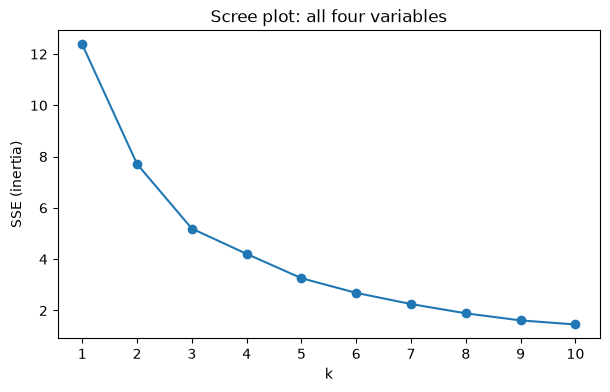

SSE values for Scree plot: all four variables:
 k    SSE
 1 12.372
 2  7.710
 3  5.193
 4  4.207
 5  3.258
 6  2.686
 7  2.251
 8  1.889
 9  1.613
10  1.454


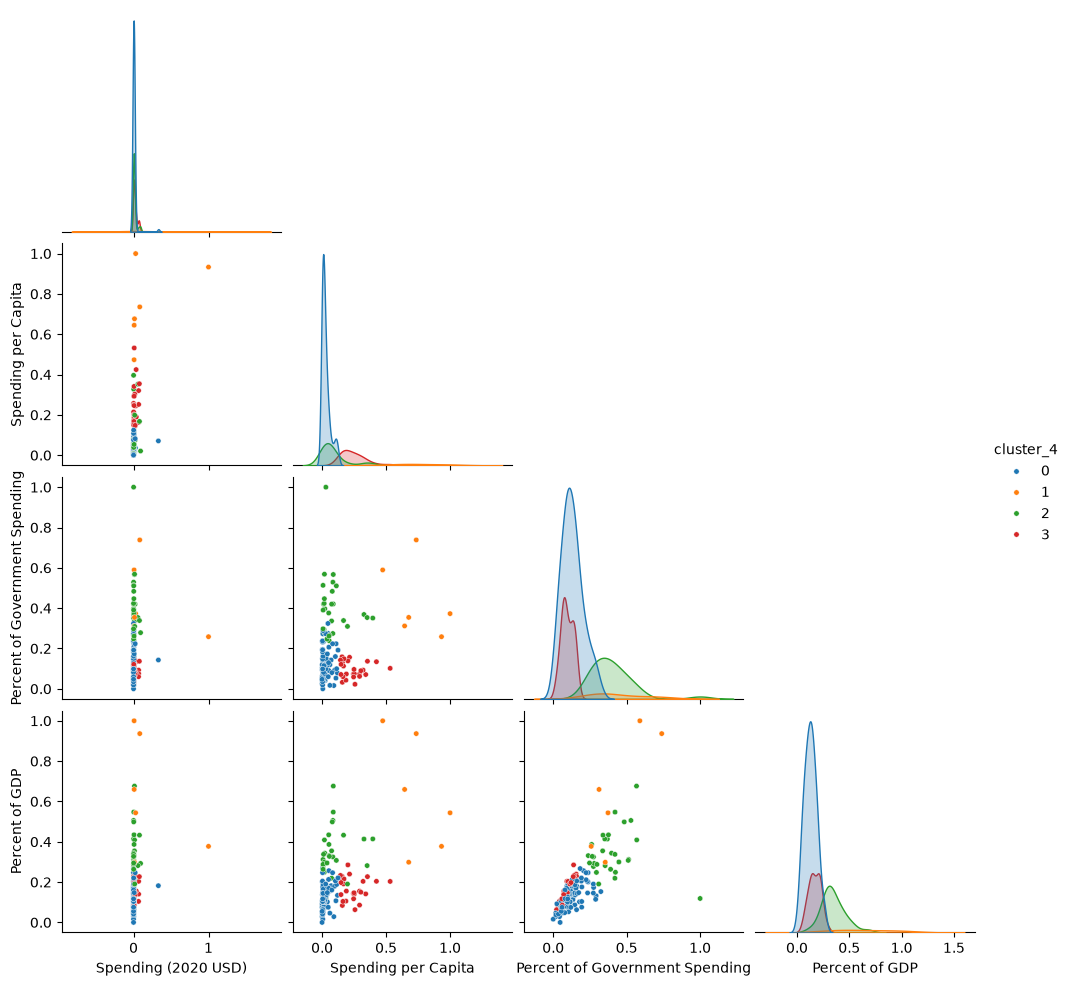

United States cluster:
                      Country  cluster_4
144  United States of America          1
Cluster 0 (86 countries): ['China', 'Brazil', 'Turkey', 'Indonesia', 'Mexico', 'Thailand', 'Chile', 'Romania', 'Bangladesh', 'Egypt', 'Philippines', 'Malaysia']
Cluster 1 (6 countries): ['United States of America', 'Saudi Arabia', 'Israel', 'Singapore', 'Kuwait', 'Oman']
Cluster 2 (30 countries): ['India', 'Russia', 'Korea, South', 'Iran', 'Taiwan', 'Pakistan', 'Algeria', 'Colombia', 'Ukraine', 'Iraq', 'Morocco', 'Myanmar']
Cluster 3 (26 countries): ['United Kingdom', 'Germany', 'France', 'Japan', 'Italy', 'Australia', 'Canada', 'Spain', 'Poland', 'Netherlands', 'Norway', 'Switzerland']

Cluster sizes:
cluster_4
0    86
1     6
2    30
3    26
dtype: int64

Cluster means:
           Spending (2020 USD)  Spending per Capita  \
cluster_4                                             
0                     4513.544               70.291   
1                   147964.582             1875.1

In [7]:
# Your Phase 2 solution to the problem goes here.
# 1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    return pd.concat([gdf1,gdf2,gdf3], ignore_index=True)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5,
            1.0: df1_0, 2.0: df2_0}

# 1.2
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)

for ax, (noise, data) in zip(axes, datasets.items()):
    sns.scatterplot(data=data, x='x1', y='x2', hue='group',
                    hue_order=['a', 'b', 'c'], ax=ax, s=20)
    ax.set_title(f'noise = {noise}')

plt.tight_layout()
plt.show()

# 1.3
def calculate_sse(X, ks=range(1, 11)):
    return [KMeans(n_clusters=k, n_init=10, random_state=0)
            .fit(X).inertia_ for k in ks]

ks = range(1, 11)
sse = {}

for noise, data in datasets.items():
    sse[noise] = calculate_sse(data[['x1', 'x2']])

# Separate scree plots preserve each SSE scale
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, noise in zip(axes, datasets):
    ax.plot(ks, sse[noise], marker='o')
    ax.set_title(f'Scree plot, noise = {noise}')
    ax.set_xlabel('k')
    ax.set_ylabel('SSE (inertia)')
    ax.set_xticks(list(ks))

plt.tight_layout()
plt.show()

# Combined plot shows differences between noise levels
plt.figure(figsize=(8, 5))

for noise in datasets:
    plt.plot(ks, sse[noise], marker='o', label=f'noise = {noise}')

plt.xlabel('k')
plt.ylabel('SSE (inertia)')
plt.title('Scree plots for all noise levels')
plt.legend()
plt.show()

# Display SSE values to help compare elbow locations
sse_table = pd.DataFrame(sse, index=ks)
sse_table.index.name = 'k'
print('SSE values by noise level:')
print(sse_table.round(2))


# 2.1
raw = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

# Filter to 2020 and remove missing rows
df = raw[raw['Year'] == 2020].dropna().copy()
df = df.drop(columns=['index', 'Year']).reset_index(drop=True)

numeric_cols = ['Spending (2020 USD)', 'Spending per Capita',
                'Percent of Government Spending', 'Percent of GDP']

# Verify that the data is clean before clustering
print('Dataset shape:', df.shape)
print('Number of countries:', len(df))
print('Missing values:\n', df.isna().sum())
print('Duplicate countries:', df['Country'].duplicated().sum())
print('Data types:\n', df.dtypes)
print('Invalid numeric values:', (~np.isfinite(df[numeric_cols])).sum().sum())
print('Negative numeric values:\n', (df[numeric_cols] < 0).sum())
print(df[numeric_cols].describe())

assert len(df) == 148, 'Unexpected number of countries'
assert df['Country'].is_unique, 'Duplicate countries found'
assert np.isfinite(df[numeric_cols].to_numpy()).all(), 'Invalid values found'

# 2.2
def maxmin(x):
    # Prevent division by zero when all values are equal
    spread = x.max() - x.min()
    if spread == 0:
        return pd.Series(0.0, index=x.index)
    return (x - x.min()) / spread

def scree(X, title):
    ks = range(1, 11)
    sse = calculate_sse(X, ks)

    plt.figure(figsize=(7, 4))
    plt.plot(ks, sse, marker='o')
    plt.xlabel('k')
    plt.ylabel('SSE (inertia)')
    plt.title(title)
    plt.xticks(list(ks))
    plt.show()

    print(f'SSE values for {title}:')
    print(pd.DataFrame({'k': list(ks), 'SSE': sse}).round(3).to_string(index=False))

def cluster_members(data, col, k):
    for c in range(k):
        names = data.loc[data[col] == c].sort_values(
            'Spending (2020 USD)', ascending=False)['Country'].tolist()
        print(f'Cluster {c} ({len(names)} countries): {names[:12]}')

def cluster_summary(data, col, variables):
    print('\nCluster sizes:')
    print(data.groupby(col).size())

    print('\nCluster means:')
    print(data.groupby(col)[variables].mean().round(3))

    print('\nCluster describe table:')
    print(data.groupby(col)[variables].describe())

def label_us(ax, data, x, y):
    us = data[data['Country'] == 'United States of America']
    if not us.empty:
        ax.annotate('United States',
                    (us.iloc[0][x], us.iloc[0][y]),
                    xytext=(6, 6), textcoords='offset points',
                    fontsize=9)

vars2 = ['Spending (2020 USD)', 'Spending per Capita']
X2 = df[vars2].apply(maxmin)

scree(X2, 'Scree plot: Spending and Spending per Capita')

k2 = 4
df['cluster_2'] = KMeans(
    n_clusters=k2, n_init=10, random_state=0
).fit_predict(X2)

# Use normalized values to compare variables on the same scale
plot2 = X2.copy()
plot2['cluster_2'] = df['cluster_2']
plot2['Country'] = df['Country']

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=plot2, x=vars2[0], y=vars2[1],
                hue='cluster_2', palette='tab10', ax=ax)
label_us(ax, plot2, vars2[0], vars2[1])
ax.set_title('k = 4 clusters on Spending and Spending per Capita')
ax.set_xlabel('Normalized Spending (2020 USD)')
ax.set_ylabel('Normalized Spending per Capita')
plt.show()

print('United States cluster:')
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster_2']])

cluster_members(df, 'cluster_2', k2)
cluster_summary(df, 'cluster_2', vars2)


# 2.3
vars3 = ['Percent of Government Spending', 'Percent of GDP']
X3 = df[vars3].apply(maxmin)

scree(X3, 'Scree plot: % of Government Spending and % of GDP')

k3 = 3
df['cluster_3'] = KMeans(
    n_clusters=k3, n_init=10, random_state=0
).fit_predict(X3)

plot3 = X3.copy()
plot3['cluster_3'] = df['cluster_3']
plot3['Country'] = df['Country']

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=plot3, x=vars3[0], y=vars3[1],
                hue='cluster_3', palette='tab10', ax=ax)
label_us(ax, plot3, vars3[0], vars3[1])
ax.set_title('k = 3 clusters on % of Government Spending and % of GDP')
ax.set_xlabel('Normalized % of Government Spending')
ax.set_ylabel('Normalized % of GDP')
plt.show()

print('United States cluster:')
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster_3']])

cluster_members(df, 'cluster_3', k3)
cluster_summary(df, 'cluster_3', vars3)


# 2.4
vars4 = vars2 + vars3
X4 = df[vars4].apply(maxmin)

scree(X4, 'Scree plot: all four variables')

k4 = 4
df['cluster_4'] = KMeans(
    n_clusters=k4, n_init=10, random_state=0
).fit_predict(X4)

# Compare all four normalized variables visually
plot4 = X4.copy()
plot4['cluster_4'] = df['cluster_4']

sns.pairplot(plot4, hue='cluster_4', palette='tab10',
             plot_kws={'s': 15}, corner=True)
plt.show()

print('United States cluster:')
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster_4']])

cluster_members(df, 'cluster_4', k4)
cluster_summary(df, 'cluster_4', vars4)

# Compare how country memberships change across the three methods
print('\nCountry cluster comparison:')
print(df[['Country', 'cluster_2', 'cluster_3', 'cluster_4']]
      .sort_values('Country').to_string(index=False))

print('\nCluster cross-tabulations:')
print(pd.crosstab(df['cluster_2'], df['cluster_3']))
print(pd.crosstab(df['cluster_2'], df['cluster_4']))
print(pd.crosstab(df['cluster_3'], df['cluster_4']))


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI generated code improves my original solution by making the clustering analysis more organized and easier to interpret. For Question 1, it uses consistent axis limits and colors across the scatterplots, adds a combined scree plot, and prints SSE values to make comparing noise levels easier. For Question 2, it checks for missing values, duplicate countries, and invalid data before clustering. It also improves the normalization function to prevent division by zero and adds cluster sizes, mean spending values, and country membership lists to help explain the results. One limitation with the original AI suggestions was that combining all scree plots could make comparisons difficult because the SSE scales vary significantly. I kept the separate plots while adding a combined version for reference. I also kept the original `.describe()` tables instead of replacing them with simpler summaries. The revised code includes checks for the expected 148 countries and compares cluster assignments across different spending variables. My main remaining concerns are that KMeans results depend on the selected number of clusters, extreme spending values can influence the results, and different variables can produce different groupings of countries.